<a href="https://colab.research.google.com/github/100522401/P1_AA_100522396_100522401/blob/main/notebooks/Cuaderno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 1 NIA 100522396 NIA 100522401


# 1. Introducción



El objetivo de la práctica es **construir un modelo** de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo. Para construir ese modelo nos basaremos en la información demográfica, financiera e interacciones de los clientes.

Como variable objetivo del problema tenemos 'deposit'. Esta variable indicará si el cliente contrató, o no, el producto ofrecido. Por tanto, se trata de un problema de **clasificación binaria**.
<br><br>
En este cuaderno se incluye:

  - Exploratory Data Analysis (EDA).
  - Definir una estrategia de evaluación.
  - Optimización de hiperparámetros (HPO).
  - Selección del mejor modelo y estudio de su rendimiento.
  - Entrenamiento del modelo final.

# 2. Configuración inicial y carga de datos

En esta sección se importan las librerías básicas usadas, se fija la semilla con el nía 1005224**01** y se cargan los datos desde Google Drive

En primer lugar, se importan las librerías básicas y fijamos la semilla aleatoria.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 100522401
np.random.seed(SEED)


Cargamos el dataset de entrenamiento desde Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/P1_AA_datasets"
TRAIN_PATH = f"{BASE_DIR}/bank_01.pkl"
# COMP_PATH  = f"{BASE_DIR}/bank_competition.pkl"

print("TRAIN_PATH:", TRAIN_PATH)
# print("COMP_PATH:", COMP_PATH)

Mounted at /content/drive
TRAIN_PATH: /content/drive/MyDrive/P1_AA_datasets/bank_01.pkl


Se comprueba que el dataset se ha cargado correctamente

In [3]:
#TODO: Se podrían añadir try/excepts al read...

data = pd.read_pickle(TRAIN_PATH)
display(data.head())
print("\nDatos cargados correctamente.")

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



Datos cargados correctamente.


# 3. EDA

En esta sección se realiza un análisis exploratorio de los datos (EDA) básico.

En este estudio determinaremos:

- Número de instancias.
- Número de variables ( incluyendo la variable objetivo).
- Identificación de variables numéricas, categóricas u ordinales.
- Estudio de cardinalidad.
- Análisis de la variable 'pdays'.
- Estudio de los valores faltantes, constantes o identificadores.
- Estudio del problema y análisis de desbalanceos de la variable objetivo.


## 3.1 Tamaño del dataset y tipo de problema

En este bloque se calcula el tamaño del dataset (número de instancias y variables). También se verfiica que la variable objetivo existe. Se comprueba cuántos valores únicos tienen deposit para confirmar el tipo de problema.

In [4]:
#Tamaño del dataset y tipo de problema
n_rows, n_cols = data.shape
print(f"Instancias: {n_rows}")
print(f"Variables totales (incluyendo target): {n_cols}")

target = "deposit"
if target not in data.columns:
    raise ValueError(f"No existe la variable objetivo '{target}' en el dataset.")

n_unique_target = data[target].nunique(dropna=False)
print(f"Variable objetivo: {target}")
print(f"Valores únicos en target: {n_unique_target}")

# La variable 'deposit' indica si suscribe o no: problema de clasificación binaria.
if n_unique_target == 2:
    problem_type = "clasificación binaria"
else:
    problem_type = "clasificación (revisar codificación de clases)"

print(f"Tipo de problema: {problem_type}")

Instancias: 11000
Variables totales (incluyendo target): 17
Variable objetivo: deposit
Valores únicos en target: 2
Tipo de problema: clasificación binaria


En este caso tenemos dos clases, y por lo tanto se concluye que es un problema de **clasificación binaria** (se suscribe o no se suscribe). Es importante tener esto en cuenta ya que condiciona la elección de modelos y métricas en el resto de la práctica.

## 3.2 Tipos de variables

En este bloque se identifican los tipos de variables, separandolas en numéricas (donde se incluyen als booleanas) y categóricas. Esta distinción nos ayudará a definir el preprocesado, ya que las variables numéricas y categóricas requieren transformaciones distintas.

In [5]:
# 2) Tipos de variables
X = data.drop(columns=[target])

num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Numéricas: {len(num_cols)}")
print(num_cols)
print("\nCategóricas: {0}".format(len(cat_cols)))
print(cat_cols)

Numéricas: 7
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categóricas: 9
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


Se han identificado 7 variables numéricas y 9 variables catagóricas. Esta separación nos sirve para construir las pipelines de preprocesado, aplicando transformaciones especificas a cada tipo de variable.

## 3.3 Cardinalidad en variables categóricas

Ahora calcularemos la cardinalidad (número de valores únicos) de las variables categóricas para detectar posibles casos de alta cardinalidad. Es importante tenerlo en cuenta porque al aumentar la dimensionalidad del conjunto de datos, aumenta el coste computacional y el rendimiento del modelo.

In [6]:
# 3) Cardinalidad en variables categóricas
if len(cat_cols) == 0:
    print("No hay variables categóricas.")
else:
    cardinality = X[cat_cols].nunique(dropna=False).sort_values(ascending=False)
    display(cardinality.to_frame("n_unique"))

    high_card_cols = cardinality[cardinality > 10].index.tolist()
    if high_card_cols:
      print("\nCategóricas con alta cardinalidad (>10):", high_card_cols)
    else:
      print("\nCategóricas con alta cardinalidad (>10): ninguna")

,n_unique
job,13
month,12
education,5
poutcome,4
marital,3
contact,3
default,2
housing,2
loan,2



Categóricas con alta cardinalidad (>10): ['job', 'month']


En este caso, se observa que hay dos columnas que superan el umbral de alta caridnalidad (> 10 valores únicos).

## 3.4 Valores faltantes

A continuación analizaremos los valores faltantes del dataset, calculando para cada variable cuántos valores nulos aparecen y qué porcentaje representan. Esta información es importante para decidir quÉ estrategia se utilizará en el preprocesado (imputación)

In [7]:
# 4) Valores faltantes
missing_count = data.isna().sum().sort_values(ascending=False)
missing_ratio = (missing_count / len(data) * 100).round(2)
missing_df = pd.DataFrame({"n_missing": missing_count, "pct_missing": missing_ratio})
missing_df = missing_df[missing_df["n_missing"] > 0]

if missing_df.empty:
    print("No hay valores faltantes.")
else:
    display(missing_df)


,n_missing,pct_missing
education,316,2.87
job,169,1.54


Se observa que hay dos varibales con valores faltantes. Estas variables requerirán una estrategia de imputación en el preprocesado, que constará en el pipeline. Esto evitará problemas durante el entrenamiento de los modelos.

## 3.5 Columnas constantes o tipo ID

Se buscan posibles columnas problemáticas para el modelado: columnas constantes y columnas tipo ID (con valores casi únicos o identificables). ESte tipo de variables aporta poca capacidad predicitiva y puede introducir ruido o sobreajusnte, por lo que es mejor detectarlas antes del preprocesado.

In [8]:
# 5) Columnas constantes y posibles ID
nunique = X.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()

id_like_by_name = [c for c in X.columns if "id" in c.lower()]
id_like_by_uniqueness = [c for c in X.columns if X[c].nunique(dropna=False) >= 0.98 * len(X)]
id_like_cols = sorted(set(id_like_by_name + id_like_by_uniqueness))

print("Columnas constantes:", constant_cols if constant_cols else "ninguna")
print("Posibles columnas ID:", id_like_cols if id_like_cols else "ninguna")

Columnas constantes: ninguna
Posibles columnas ID: ninguna


No se han detectado **columnos constantes** ni **posibles columnas tipo ID** en el dataset. Por tanto, no es necesario eliminar variables por estos motivos en el preprocesado y modelado.

## 3.6 Desbalanceo del target

Ahora analizaremos la distribución de la variable objetivo **deposit**, ya que en problemas de clasificación el desbalanceo relevante relamente es el de las clases que se buscan predecir. Esta información nos será útil para justificar la elección de la métrica y la comparación entre modelos.

En este bloque se analiza la variable **pdays**, la cual representa el númerod e dúas desde el último contacto en la campaña anterior y tomará el valor **-1** cuando el cliente no ha sido contactado previamente. ENtonces, calcularemos la proporcion de valores -1 y se describen los valores válidos (pdays!=-1) para decidir como tratar la variable en el preprocesado.

Conteo por clase:
deposit
no     5780
yes    5220
Name: count, dtype: int64

Porcentajes (%):
deposit
no     52.55
yes    47.45
Name: proportion, dtype: float64

Imbalance ratio (mayor/minor): 1.11


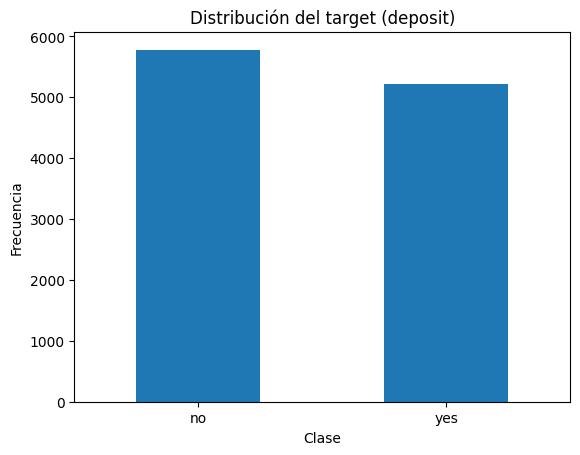

In [9]:
# Desbalanceo del target

counts = data[target].value_counts(dropna=False)
perc = data[target].value_counts(normalize=True, dropna=False) * 100

# Conteo y porcentaje por clase
print("Conteo por clase:")
print(counts)

print("\nPorcentajes (%):")
print(perc.round(2))

# Ratio de desbalanceo (mayor/minor)
imbalance_ratio = counts.max() / counts.min()
print("\nImbalance ratio (mayor/minor):", round(imbalance_ratio, 2))

# Gráfico
ax = counts.plot(kind="bar")
plt.title("Distribución del target (deposit)")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.xticks(rotation=0)
plt.show()

La variable objetivo presenta una distribución de 52,55% para la clase no y 47,45% para la clase yes. Por tanto, el problema puedoe considerarse prácticamente equilibrado, con un desbalanceo poco notorio.

## 3.7 Análisis pdays

In [10]:
# Analisis de pdays
p = data["pdays"]

n_total = len(p)
n_minus1 = (p == -1).sum()
pct_minus1 = 100 * n_minus1 / n_total

print(f"Total: {n_total}")
print(f"pdays = -1 (sin contacto previo): {n_minus1} ({pct_minus1:.2f}%)")

p_valid = p[p != -1]
print("\nResumen pdays (solo contactos previos reales):")
n_notminus1 = (p != -1).sum()
pct_notminus1 = 100 * n_notminus1 / n_total
print(f"pdays != -1 (solo contactos previos reales): {n_notminus1} ({pct_notminus1:.2f}%)")

display(p_valid.describe())



Total: 11000
pdays = -1 (sin contacto previo): 8203 (74.57%)

Resumen pdays (solo contactos previos reales):
pdays != -1 (solo contactos previos reales): 2797 (25.43%)


,pdays
count,2797.000000
mean,204.718627
std,122.397953
min,1.000000
25%,98.000000
50%,182.000000
75%,286.000000
max,854.000000


## TODO, modificar esto, metido en pipeline

Se observa que **pdays == -1** aparece en **8203 de 11000 instancias (74.57%)**, lo que indica que en al mayoría de los casos no existe un contacto previo. Por tanto, el valor -1 no debe interpretarse como un valor numérico, ya que no aporta informaciónr relevante al modelado. Para los casos de **pdays != -1**, el número de días tiene una distribución amplia ( mediana **182**, rango **1 - 854**), lo que aporta información que puede ser útil para el modelado.

En este bloque se dine el preprocesado de **pdays**. Dado que **pdays == -1** no representa un número de días real, sino "sin contacto previo", separemos esta información en una **variable binaria (contacted_before)** y se trasnforma pdays para que contenga únicamente valores numéricos válidos, reemplazando -1 por NaN. De este modo se evita que -1 distorsione el escalado de la variable.

In [11]:
# # Preprocesado pdays

def transform_pdays(X):
  X = X.copy()
  X["contacted_before"] = (X["pdays"] != -1).astype(int)
  X["pdays"] = X["pdays"].replace(-1, np.nan)
  return X

print("Función transform_pdays definida correctamente.")

Función transform_pdays definida correctamente.


## 3.8 Conclusiones EDA TODO

# 4. Estrategia de evaluación

# 4.1 Evaluación outer




En este bloque se define la **evaluación outer** de la práctica. Para ello, se separan las variables predictoras (`X`) y la variable objetivo (`y`). A continuación se realiza una partición **holdout**, reservando **2/3 de los datos para entrenamiento y 1/3 para test**.

El conjunto de test quedará reservado hasta el final de la práctica, lo que nos permitirá obtener un aestimación sobre el rendimiento del modelo sobre datos no vistos.

Además, en este bloque se realiza una **modificación sobre la variable objetivo** (`deposit`) ya que exisdten modelos que así lo requieren. La variable pasa de ser una variabe `yes/no` a ser una **variable binaria** `1/0`. Más concretamente `no -> 0` y ` yes -> 1` . Esta modificación no cambia el significado del problema, sino únicamente la representación de la variable objetivo.

In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold

#Todas las columnas menos la target
X = data.drop(columns='deposit')
#Solo columna target
y = data['deposit']

# Convertir target a variable binaria
y = y.map({"no": 0, "yes": 1})

# Hacemos particiones
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

print("Distribución de clases en y_train (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución de clases en y_test (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Tamaño de X_train: (7333, 16)
Tamaño de X_test: (3667, 16)
Distribución de clases en y_train (%):
deposit
0    52.54
1    47.46
Name: proportion, dtype: float64

Distribución de clases en y_test (%):
deposit
0    52.55
1    47.45
Name: proportion, dtype: float64


## 4.2 Métrica principal

En esta práctica se utilizará **F1-score** como métrica principal para comparar modelos y seleccionar los hiperparámetros. Se elige esta métrica pese a tener un problema con un desavalanceo leve ya que resume en un único valor el equilibrio entre **precision** y **recall**. Esto permitirá evaluar la capacidad del modelo para identificar los TP o **verdaderos positivos** sin penalizar excesivamente

Además del F1-score, se añadiran métricas complementarias:


*   **Accuracy**: al tratarse de un problema relativamente equilibrado, aporta información que puede ser útil sobre el porcentaje de aciertos del modelo.
*   **ROC AUC**: resulta útil como métrica complemetaria ya que mide la capacidad del modelo para separar las distintas clases.
* **Precision**: para valorar la fiabilidad de las predicciones positivas.
* **Recall**: para medir la capacidad del modelo de detectar casos positivos reales.

De esta manera, el **F1-score** será la referencia principal en la comparación entre alternativas, mientras que el resto de métricas se utilizarán como apoyo a la hora de interpretar resultados.



In [23]:
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

# Métrica principal
f1_scorer = make_scorer(f1_score, pos_label=1)

# Métricas complementarias
SCORING = {
    "f1": make_scorer(f1_score, pos_label=1),
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1),
    "recall": make_scorer(recall_score, pos_label=1),
    "roc_auc": "roc_auc"
}

## 4.3 Evaluación inner

La evaluación interna **inner** se realizará mediante una **validación cruzada estratificada de 3 particiones** sobre el conjunto de entrenamiento `X__trai` `Ỳ_train`. Se hará uso de esta estrategia para:
* Comparar modelos
* Seleecionar el mejor scaler
* Ajustar hiperparámetros (HPO)

In [24]:
# Se define la validación cruzada (3-fold)
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

print('\n')
print(cv_inner)



StratifiedKFold(n_splits=3, random_state=100522401, shuffle=True)


Se utilizará el F1-score como métrica principal de evaluación, ya que se trata de un problema de clasificación binaria y nos interesa medir de forma equilibrada la capacidad del modelo para identificar correctamente la clase positiva. Aunque el desbalanceo no es muy significativo, la accuracy puede ser menos representativa, mientras que el F1-score combina precisión y recall en una única medida y permite comparar mejor el rendimiento de los distintos modelos.

# 5. Pipeline de preprocesado


## 5.1 Preprocesado

En esta sección se define la pipeline de preprocesado que se aplicará a los datos antes de entrenar cada modelo. La pipeline se encargará de realizar las transformaciones adecuadas para cada tipo de variable garantizando que estas se realicen de manera consistente. Más concretamente, el pipeline se encargará de:
* **Variables numéricas**: Se tratarán los valores faltantes mediante imputación con la mediana. También, en caso de ser necesario, se usará escalado de las variables.

*  **Variables categórcas**: Se tratarán los valores faltantes con la categoría más frecuente o moda. A continuación se codificará mediante **One-Hot Encoding**.

* **Variable** `pdays`: como se ha ha estudiado en el EDA, el valor `-1` no representa el número de días real, sino ausencia de contacto previo. Por tanto se aplicará un tratamiento específico dentro de la pipeline.

## 5.2 Pipeline

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

def build_preprocessor(num_cols, cat_cols, numeric_scaler=None):
    """Construye el preprocesado para variables numericas y categoricas."""

    # Pipeline para las variables numéricas: imputar NaN con mediana + scaler
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if numeric_scaler is not None:
        numeric_steps.append(("scaler", numeric_scaler))
    numerical_pipeline = Pipeline(numeric_steps)

    # Pipeline para categóricas: imputar NaN con moda + OneHotEncoder
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # ColumnTransformer: Se aplican las transformaciones según el tipo de variable
    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ])

    return preprocessor


def create_pipeline(model, num_cols, cat_cols, numeric_scaler=None):
    """Une el preprocesado y el modelo final en una sola pipeline."""

    preprocessor = build_preprocessor(
        num_cols,
        cat_cols,
        numeric_scaler=numeric_scaler
    )

    return Pipeline([
        ("transform_pdays", FunctionTransformer(transform_pdays)),
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])


print("Pipeline base de preprocesado definida correctamente.")


Pipeline base de preprocesado definida correctamente.


En este bloque se define una función para construir pipelines. La pipeline integra el tratamiento específico de `pdays`, la imputación de valores faltantes,la codificación de variables categóricas y, en caso de ser necesarios, el escalado de variables numéricas.

##5.3 Preparación de columnas

Al definir el preprocesado, las variables numéricas y categóricas se identifican a partir del conjunto de entrenamiento.

Además, como la variable `contacted_before` se genera dentro de la pipeline a partir de `pdays`, es necesario añadirla manualmente a la lista de variables numéricas para poder recibir el tratamiento adecuado en el `ColumnTransformer`.

In [16]:
num_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

if "contacted_before" not in num_cols:
    num_cols = num_cols + ["contacted_before"]

# 6. Métodos básicos: KNN y árboles

## 6.1 Selección del mejor scaler para KNN

En esta sección se comparan los diferentes scalers propuestos para determinar cual esd el más adecuado para **KNN** en este problema. Más concretamente se evaluarán el **StandardScaler**, **MinMaxScaler** y **RobustScaler** usando **KNN con hiperparametros por defecto**.

La comparación entre las distintas alternativas se realiza siguiendo la estrategia de evaluación definida anteriormente, tomando el **F1-score-medio** como criterio principal y utilizando el resto de métrica como apoyo a la hora de interpretar los resultados.


In [26]:
import time
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Se definen los scalers a comparar
scalers = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "robust": RobustScaler(),
}

# Lista donde se almacenarán los resultados
scaler_results = []

# 3-fold crossvalidation scalers
for scaler_name, scaler in scalers.items():
  # Se crea la pipeline con KNN y scaler actual
    knn_pipe = create_pipeline(
        KNeighborsClassifier(),
        num_cols=num_cols,
        cat_cols=cat_cols,
        numeric_scaler=scaler
    )

    start = time.perf_counter()

    cv_out = cross_validate(
        knn_pipe,
        X_train,
        y_train,
        cv=cv_inner,
        scoring = SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )
    elapsed = time.perf_counter() - start

    # Se guardan las medias y desviaciones de las métricas
    scaler_results.append({
        "scaler": scaler_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),  # Desviación estándar f1-score
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })

# Se muestran los resultados
scaler_results_df = pd.DataFrame(scaler_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(scaler_results_df)

best_scaler_name = scaler_results_df.loc[0, "scaler"]
best_scaler = scalers[best_scaler_name]
print(f"\nMejor scaler para KNN según F1 medio: {best_scaler_name}")

,scaler,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,standard,0.775376,0.011051,0.795174,0.808546,0.744828,0.863080,0.065379,0.359219,3.038688
1,robust,0.745040,0.020404,0.766538,0.773423,0.718678,0.838882,0.058098,0.378024,0.892084
2,minmax,0.690235,0.010215,0.729579,0.756442,0.634770,0.789718,0.054475,0.346458,0.757487



Mejor scaler para KNN según F1 medio: standard


De esta comparación se puede concluir que **StandardScaler** es el scaler que ofrece el mejor rendimiento para KNN, ya que obtiene los valores más altos en todas las métricas evaluadas.

Se observa también que **RobustScaler** ocupa una posición intermedia, con un rendimiento inferior al de StandardScaler pero superior al de MinMaxScaler. Por último, **MinMaxScaler** es el scaler que presenta los peores resultados.

Consecuentemente y a partir de este punto, el scaler seleccionado será **StandardScaler**, y por tanto, se empleará cuando el modelo necesite ser escalado.


## 6.2 KNN con hiperparámetros por defecto

En esta sección se evalúa un modelo **KNN** con sus hiperparámetros por defecto, utilizando el método de escalado ya seleccionado(**StandardScaler**). EL objetivo es obtener una referencia inicial del rendimiento antes de realizar la HPO.

Además se medirá el tiempo de entrenamiento, ya que el coste computacional tendrá también peso en la comparación.

In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Inner crossvalidation
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Pipeline
pipeline_knn_default = create_pipeline(
    model=KNeighborsClassifier(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Tiempo
start = time.perf_counter()

scores_knn_default = cross_validate(
    pipeline_knn_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
  )

elapsed = time.perf_counter() - start

print("KNN con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_knn_default['test_f1'].mean():.4f} ± {scores_knn_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_knn_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_knn_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_knn_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_knn_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_knn_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

KNN con hiperparámetros por defecto:

F1 medio: 0.7754 ± 0.0111

Accuracy medio: 0.7952
Precision media: 0.8085
Recall medio: 0.7448
ROC-AUC medio: 0.8631
Tiempo medio de fit: 0.0561 s
Tiempo total CV: 0.7762 s


##6.3 HPO de KNN
Una vez ya se ha evaluado el KNN con sus hiperparámetros por defecto, en esta subsección se ajustan sus hiperparámetros mediante un `Grid Search` o búsqueda en rejilla y validación cruzada de 3 particiones. EL objetivo es comprobar si es posible mejorar el rendimiento del modelo y analizar si la mejora compensa el posible aumento del coste computacional.


In [36]:
from sklearn.model_selection import GridSearchCV

# Pipeline KNN
pipeline_knn = create_pipeline(
    model=KNeighborsClassifier(),
    num_cols=num_cols,
    cat_cols=cat_cols,
    numeric_scaler=StandardScaler()
)

# Grid
param_grid_knn = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    scoring=f1_scorer,
    cv=cv_inner,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

#Tiempo
start = time.perf_counter()

grid_knn.fit(X_train, y_train)

elapsed = time.perf_counter() - start

#Resultados
print("KNN con HPO")
print("Mejores hiperparámetros para KNN:", grid_knn.best_params_)
print(f"Mejor F1 medio: {grid_knn.best_score_:.4f}")
print(f"Tiempo total HPO: {elapsed:.4f} segundos")

KNN con HPO
Mejores hiperparámetros para KNN: {'classifier__n_neighbors': 11, 'classifier__p': 2, 'classifier__weights': 'distance'}
Mejor F1 medio: 0.7844
Tiempo total HPO: 45.3345 segundos


Tras la optimización de hiperparámetros, el mejor modelo KNN se obtiene con **11 neighbors**, distancia de **Minkowski** con `p = 2`, que es equivalente a la **distancia euclídea** y la ponderación por distancia (`weights = "distance"`). Por tanto, con esta configuración se obtiene que el modelo alcanza un **F1-score medio de 0.7844**.

Conparado con el **KNN por defecto**, podemos observar una **ligera mejora** en el rendimiento, ya que el F1-score pasa de 0.775 a 0.784 aproximadamente. Esto indica que el ajuste de hiperparámetros sí aporta una ganancia, pero esta no es muy grande. Sin embargo, esta mejora implica un **coste computacional considerablemente mayor**, ya que el proceso de HPO ha requerido **45.33 segundos**.

En cuanto a las conclusiones de la mejor configuración, el hecho de que esta use 11 neighbours sugiere que, en este caso, KNN funciona mejor con un número de vecinos mediano. Además, es uso de distancias indica que resulta beneficioso dar más importancia a los vecinos más cercanos.

# Análisis del efecto de los hiperparámetros en KNN

En esta sección se analiza cómo afectan los principales hiperparámetros de KNN al rendimiento del modelo. Concretamente se estudia el efecto del número de vecinos (`n_neighbors`), la ponderación (`weights`) y el parámetro `p`de la distancia de Minkowski.

Dadp que la mejor configuración obtenida utiliza `weights = "distance"`, `p=2`y `n_neighbors = 11`, en este apartado se irán fijando los parametros de dicha configuración para analizar de forma aislada cómo varía el rendimiento del modelo.

En primer lugar se preparan los resultados obtenidos tras realizar el `GridSearch`.

In [37]:
results_knn = pd.DataFrame(grid_knn.cv_results_)

results_knn_plot = results_knn[[
    "param_classifier__n_neighbors",
    "param_classifier__weights",
    "param_classifier__p",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].copy()

results_knn_plot = results_knn_plot.sort_values("mean_test_score", ascending=False)
display(results_knn_plot.head(10))

,param_classifier__n_neighbors,param_classifier__weights,param_classifier__p,mean_test_score,std_test_score,mean_fit_time,rank_test_score
19,11,distance,2,0.784376,0.009690,0.066306,1
11,7,distance,2,0.780516,0.006770,0.076120,2
18,11,uniform,2,0.779913,0.010908,0.066543,3
27,21,distance,2,0.779609,0.015059,0.104752,4
15,9,distance,2,0.779590,0.011487,0.119245,5
23,15,distance,2,0.778638,0.012109,0.064945,6
10,7,uniform,2,0.778325,0.007568,0.062890,7
26,21,uniform,2,0.776992,0.014374,0.108776,8
14,9,uniform,2,0.776894,0.013411,0.124281,9
22,15,uniform,2,0.776530,0.011765,0.065289,10


A continuación se muestra el plot que compara `uniform`y `distance`fijando el parámetro `p=2`.

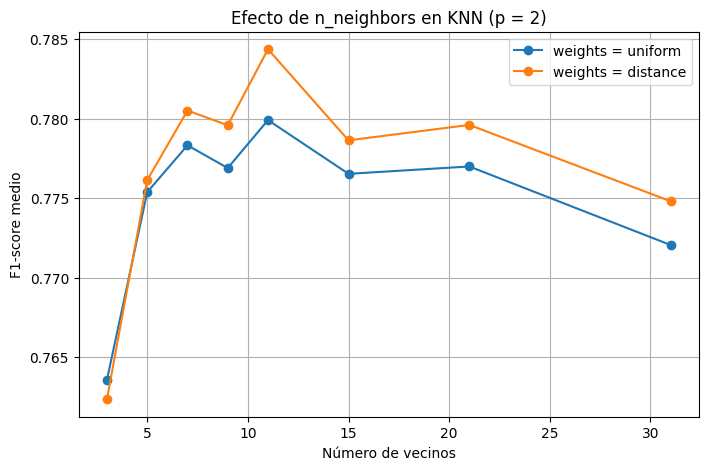

In [38]:
plt.figure(figsize=(8,5))

for weight_type in results_knn["param_classifier__weights"].unique():
    subset = results_knn[
        (results_knn["param_classifier__weights"] == weight_type) &
        (results_knn["param_classifier__p"] == 2)
    ].sort_values("param_classifier__n_neighbors")

    plt.plot(
        subset["param_classifier__n_neighbors"],
        subset["mean_test_score"],
        marker="o",
        label=f"weights = {weight_type}"
    )

plt.title("Efecto de n_neighbors en KNN (p = 2)")
plt.xlabel("Número de vecinos")
plt.ylabel("F1-score medio")
plt.legend()
plt.grid(True)
plt.show()

Se observa que ambas gráficas tienen una forma similar, pero que la gráfica referente `weights = "distance"` por lo general obtiene un **mayor F1-score medio**.

Ahora se compararán los resultados obtenidos con `p=1`y con `p=2`fijando esta vez `weights = "distance"`.

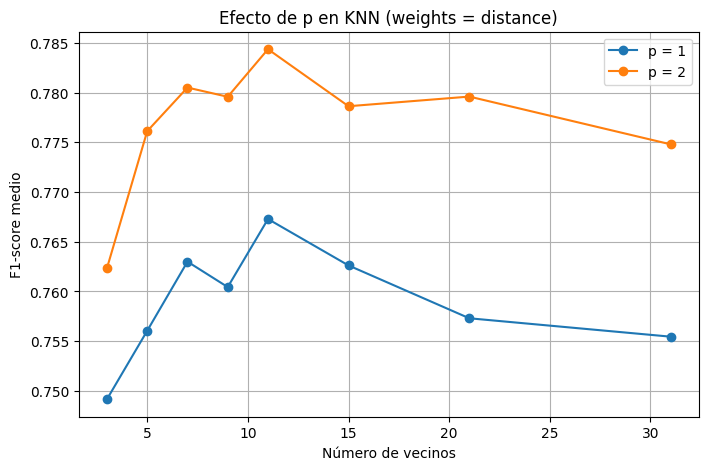

In [40]:
plt.figure(figsize=(8,5))

for p_value in results_knn["param_classifier__p"].unique():
    subset = results_knn[
        (results_knn["param_classifier__p"] == p_value) &
        (results_knn["param_classifier__weights"] == "distance")
    ].sort_values("param_classifier__n_neighbors")

    plt.plot(
        subset["param_classifier__n_neighbors"],
        subset["mean_test_score"],
        marker="o",
        label=f"p = {p_value}"
    )

plt.title("Efecto de p en KNN (weights = distance)")
plt.xlabel("Número de vecinos")
plt.ylabel("F1-score medio")
plt.legend()
plt.grid(True)
plt.show()

En este caso se observa un claro mejor rendimiento con `p=2`.

Para concluir, se observa cómo el rendimiento del modelo varía con el número de vecinos. EN general, valores muy bajos de `n_neighbors` hacen al modelo más sensible al ruido (favorece el **Overfitting**), mientras que valores más altos hacen que las fronteras de decisión sean muy suaves (puede provocar **Underfitting**). En este problema, el mejor comportamiento se alcanza con un número de vecinos intermedio.

##DummyClassifier
// este apartado luego lo movemos al final para las conclusiones

En esta sección se evalúan dos clasificadores **Dummy** para medir el rendimiento de clasificadores **triviales**. Un **DummyClassifier** no aprende patrones reales de los atributos, simplemente predice según una regla muy básica, por ejemplo escoger siempre la clase mayoritaria o generar predicciones aleatorias respetando la distribución de clases.

Esto sirve como base. Si **KNN** o los **árboles** no mejoran claramente a un **dummy**, entonces el modelo no estaría aprendiendo información útil del problema.

In [31]:
from sklearn.dummy import DummyClassifier

# Se definen los clasificadores dummy a comparar
dummy_models = {
    "most_frequent": DummyClassifier(strategy="most_frequent"),
    "stratified": DummyClassifier(strategy="stratified", random_state=SEED),
}

# Lista donde se guardan los resultados
dummy_results = []

# Evaluación de cada dummy con validación cruzada
for dummy_name, dummy_model in dummy_models.items():
    start = time.perf_counter()

    cv_out = cross_validate(
        dummy_model,
        X_train,
        y_train,
        cv=cv_inner,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start

    # Se guardan las medias de las métricas y los tiempos
    dummy_results.append({
        "modelo": dummy_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })

# Se muestran los resultados ordenados por F1 medio
dummy_results_df = pd.DataFrame(dummy_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(dummy_results_df)

,modelo,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,stratified,0.476707,0.00418,0.500613,0.474132,0.47931,0.499582,0.004642,0.018476,0.072578
1,most_frequent,0.000000,0.00000,0.525433,0.000000,0.00000,0.500000,0.005789,0.022343,0.104612


## Evaluación de árboles con hiperparámetros por defecto

A continuación se evalúa un **DecisionTreeClassifier** con sus hiperparámetros por defecto. En este caso, a diferencia de KNN, no es necesario aplicar escalado a las variables numéricas, ya que los árboles no dependen de distancias entre observaciones.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Se extraen las columnas numéricas y categóricas del train
num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Pipeline del árbol con hiperparámetros por defecto
pipeline_tree_default = create_pipeline(
    model=DecisionTreeClassifier(random_state=SEED),
    num_cols=num_cols_train,
    cat_cols=cat_cols_train,
    numeric_scaler=None
)

# Tiempo de la validación cruzada
start = time.perf_counter()

scores_tree_default = cross_validate(
    pipeline_tree_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start

print("Árbol con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_tree_default['test_f1'].mean():.4f} ± {scores_tree_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_tree_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_tree_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_tree_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_tree_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_tree_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

## Árbol poco profundo

Además del árbol con hiperparámetros por defecto, utilizamos un árbol **poco profundo** para obtener una interpretación de cómo podrían tomarse decisiones en este problema. Para ello se entrenará un árbol con profundidad reducida, lo que facilita visualizar las reglas principales de decisión.

In [ ]:
from sklearn.tree import plot_tree

# Se extraen las columnas numéricas y categóricas del train
num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Pipeline del árbol poco profundo
pipeline_tree_shallow = create_pipeline(
    model=DecisionTreeClassifier(max_depth=4, random_state=SEED),
    num_cols=num_cols_train,
    cat_cols=cat_cols_train,
    numeric_scaler=None
)

# Se ajusta el modelo para poder visualizarlo
pipeline_tree_shallow.fit(X_train, y_train)

# Se recuperan los nombres de las variables tras el preprocesado
preprocessor_fitted = pipeline_tree_shallow.named_steps["preprocessor"]
cat_feature_names = preprocessor_fitted.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols_train)
feature_names = num_cols_train + list(cat_feature_names)

# Representación gráfica del árbol
plt.figure(figsize=(24, 10))
plot_tree(
    pipeline_tree_shallow.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Árbol de decisión poco profundo (max_depth=4)")
plt.show()
